# 07 — Generalização, validação cruzada e viés–variância

O objetivo é separar **desempenho aparente** (treino) de **desempenho
retido** (teste) e entender se as diferenças são estáveis ou apenas
ruído de uma única divisão.

A métrica principal é **F1-Score macro** na classificação e **MAE** na
regressão. Para que o sinal do gap seja sempre intuitivo, definimos:

* classificação: `Gap = F1 treino − F1 teste` (positivo = piora);
* regressão: `Gap MAE = MAE teste − MAE treino` (positivo = piora) e
  `Gap R² = R² treino − R² teste` (positivo = piora).

A adaptação para métricas de erro está alinhada à orientação do
enunciado de "interpretar o sinal adequadamente".

In [1]:
from pathlib import Path
import sys
import time
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate

from src.config import *
from src.prepare_data import preparar_classificacao, preparar_regressao
from src.metrics import calcular_metricas_classificacao, calcular_metricas_regressao
from src.models import (
    carregar_modelo,
    criar_arvore_classificacao,
    criar_arvore_regressao,
)
from src.expert_system import (
    aplicar_sistema_especialista,
    aplicar_sistema_especialista_pontuacao,
)
from rules.regras_classificacao import REGRAS_CLASSIFICACAO
from rules.regras_regressao import (
    LIMITES_PONTUACAO,
    PONTUACAO_BASE,
    REGRAS_REGRESSAO,
    REGRAS_REGRESSAO_V1,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 190)
criar_diretorios()

X_train_c, X_test_c, y_train_c, y_test_c = preparar_classificacao()
X_train_r, X_test_r, y_train_r, y_test_r = preparar_regressao()

modelos_c = {
    "Árvore de Decisão": carregar_modelo("arvore_classificacao"),
    "Random Forest": carregar_modelo("rf_classificacao"),
    "Gradient Boosting": carregar_modelo("gb_classificacao"),
}
modelos_r = {
    "Árvore de Decisão": carregar_modelo("arvore_regressao"),
    "Random Forest": carregar_modelo("rf_regressao"),
    "Gradient Boosting": carregar_modelo("gb_regressao"),
}

resultado_c_treino = aplicar_sistema_especialista(X_train_c, REGRAS_CLASSIFICACAO)
resultado_c_teste = aplicar_sistema_especialista(X_test_c, REGRAS_CLASSIFICACAO)
mascara_c_treino = resultado_c_treino["conclusao"].ne("Indeterminado")
mascara_c_teste = resultado_c_teste["conclusao"].ne("Indeterminado")

pred_r_v1_treino = aplicar_sistema_especialista(
    X_train_r, REGRAS_REGRESSAO_V1
)["conclusao"].astype(float)
pred_r_v1_teste = aplicar_sistema_especialista(
    X_test_r, REGRAS_REGRESSAO_V1
)["conclusao"].astype(float)
pred_r_v2_treino = aplicar_sistema_especialista_pontuacao(
    X_train_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)["conclusao"].to_numpy()
pred_r_v2_teste = aplicar_sistema_especialista_pontuacao(
    X_test_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)["conclusao"].to_numpy()

print("Treino/teste classificação:", X_train_c.shape, X_test_c.shape)
print("Treino/teste regressão:    ", X_train_r.shape, X_test_r.shape)

Treino/teste classificação: (40000, 9) (10000, 9)
Treino/teste regressão:     (40000, 8) (10000, 8)


## 1. Desempenho no treino e no teste

No sistema especialista de classificação, as métricas só fazem sentido
nos registros cobertos por alguma regra; a cobertura é reportada junto.
Nos modelos de ML, todos os registros são classificados.

In [2]:
def linha_gap_classificacao(nome, y_tr, pred_tr, y_te, pred_te, cobertura_te):
    m_tr = calcular_metricas_classificacao(
        y_tr, pred_tr, classes=CLASSES, classe_positiva=CLASSE_POSITIVA
    )
    m_te = calcular_metricas_classificacao(
        y_te, pred_te, classes=CLASSES, classe_positiva=CLASSE_POSITIVA
    )
    return {
        "Modelo": nome,
        "F1 Macro Treino": m_tr["F1-Score (Macro)"],
        "F1 Macro Teste": m_te["F1-Score (Macro)"],
        "Gap F1 (Treino−Teste)": (
            m_tr["F1-Score (Macro)"] - m_te["F1-Score (Macro)"]
        ),
        "F1 High Teste": m_te["F1-Score (High)"],
        "Accuracy Teste": m_te["Accuracy"],
        "Cobertura Teste": cobertura_te,
    }


linhas_gap_c = [
    linha_gap_classificacao(
        "Sistema Especialista",
        y_train_c[mascara_c_treino],
        resultado_c_treino.loc[mascara_c_treino, "conclusao"],
        y_test_c[mascara_c_teste],
        resultado_c_teste.loc[mascara_c_teste, "conclusao"],
        mascara_c_teste.mean(),
    )
]

for nome, modelo in modelos_c.items():
    linhas_gap_c.append(
        linha_gap_classificacao(
            nome,
            y_train_c,
            modelo.predict(X_train_c),
            y_test_c,
            modelo.predict(X_test_c),
            1.0,
        )
    )

tabela_gap_c = pd.DataFrame(linhas_gap_c).set_index("Modelo")
display(tabela_gap_c.round(4))
tabela_gap_c.to_csv(
    TABLES_DIR / "generalizacao_classificacao.csv", encoding="utf-8"
)

,F1 Macro Treino,F1 Macro Teste,Gap F1 (Treino−Teste),F1 High Teste,Accuracy Teste,Cobertura Teste
Modelo,,,,,,
Sistema Especialista,0.5688,0.5618,0.0070,0.9539,0.8766,0.5387
Árvore de Decisão,0.7473,0.6649,0.0823,0.9119,0.8595,1.0000
Random Forest,1.0000,0.6862,0.3138,0.9160,0.8678,1.0000
Gradient Boosting,0.7506,0.6681,0.0826,0.9245,0.8790,1.0000


In [3]:
previsoes_r = {
    "Especialista v1 (4 células)": (pred_r_v1_treino, pred_r_v1_teste),
    "Especialista v2 (19 faixas)": (pred_r_v2_treino, pred_r_v2_teste),
}
for nome, modelo in modelos_r.items():
    previsoes_r[nome] = (
        modelo.predict(X_train_r),
        modelo.predict(X_test_r),
    )

linhas_gap_r = []
for nome, (pred_treino, pred_teste) in previsoes_r.items():
    m_tr = calcular_metricas_regressao(y_train_r, pred_treino)
    m_te = calcular_metricas_regressao(y_test_r, pred_teste)
    linhas_gap_r.append(
        {
            "Modelo": nome,
            "MAE Treino": m_tr["MAE"],
            "MAE Teste": m_te["MAE"],
            "Gap MAE (Teste−Treino)": m_te["MAE"] - m_tr["MAE"],
            "RMSE Teste": m_te["RMSE"],
            "R2 Treino": m_tr["R2"],
            "R2 Teste": m_te["R2"],
            "Gap R2 (Treino−Teste)": m_tr["R2"] - m_te["R2"],
            "MAPE Teste (%)": m_te["MAPE (%)"],
        }
    )

tabela_gap_r = pd.DataFrame(linhas_gap_r).set_index("Modelo")
display(tabela_gap_r.round(4))
tabela_gap_r.to_csv(
    TABLES_DIR / "generalizacao_regressao.csv", encoding="utf-8"
)

,MAE Treino,MAE Teste,Gap MAE (Teste−Treino),RMSE Teste,R2 Treino,R2 Teste,Gap R2 (Treino−Teste),MAPE Teste (%)
Modelo,,,,,,,,
Especialista v1 (4 células),11.2458,11.2721,0.0263,13.9316,0.2054,0.1964,0.0089,17.1501
Especialista v2 (19 faixas),5.9902,5.9941,0.0039,7.5255,0.7667,0.7655,0.0012,8.7747
Árvore de Decisão,5.8279,6.2824,0.4545,7.8801,0.7813,0.7429,0.0384,9.2179
Random Forest,4.5915,6.1402,1.5487,7.6629,0.8626,0.7569,0.1057,8.9851
Gradient Boosting,5.8817,5.9278,0.0461,7.3799,0.7794,0.7745,0.0049,8.6523


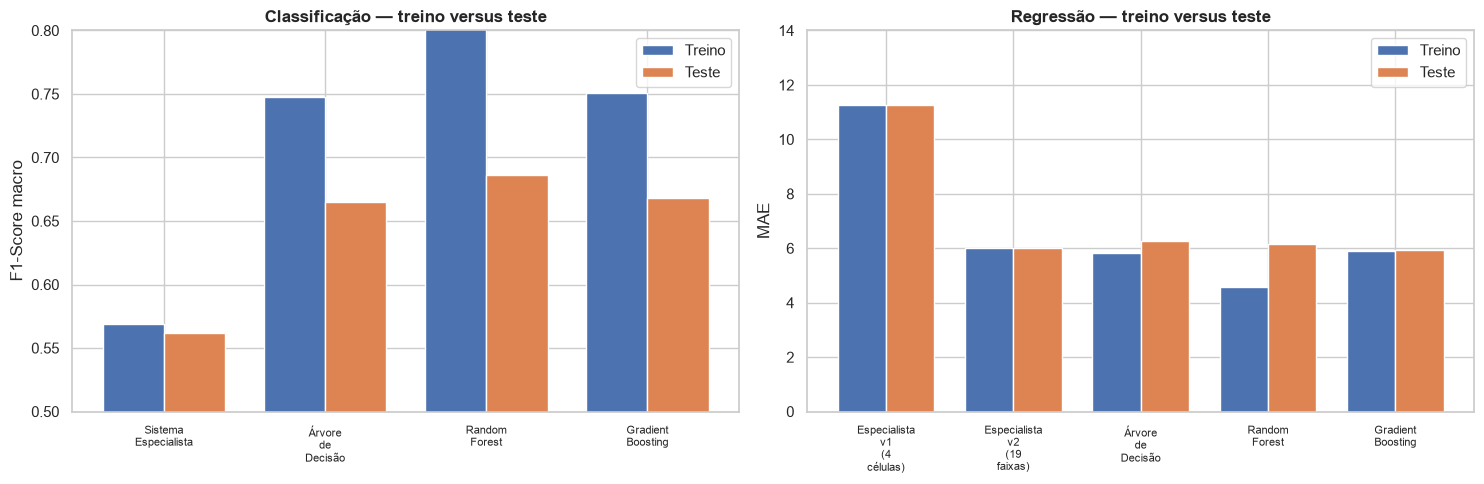

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

eixos[0].bar(
    np.arange(len(tabela_gap_c)),
    tabela_gap_c["F1 Macro Treino"],
    width=0.38,
    label="Treino",
    color="#4c72b0",
)
eixos[0].bar(
    np.arange(len(tabela_gap_c)) + 0.38,
    tabela_gap_c["F1 Macro Teste"],
    width=0.38,
    label="Teste",
    color="#dd8452",
)
eixos[0].set_xticks(
    np.arange(len(tabela_gap_c)) + 0.19,
    [texto.replace(" ", "\n") for texto in tabela_gap_c.index],
    fontsize=8,
)
eixos[0].set_ylim(0.5, 0.8)
eixos[0].set_ylabel("F1-Score macro")
eixos[0].set_title("Classificação — treino versus teste", fontweight="bold")
eixos[0].legend()

eixos[1].bar(
    np.arange(len(tabela_gap_r)),
    tabela_gap_r["MAE Treino"],
    width=0.38,
    label="Treino",
    color="#4c72b0",
)
eixos[1].bar(
    np.arange(len(tabela_gap_r)) + 0.38,
    tabela_gap_r["MAE Teste"],
    width=0.38,
    label="Teste",
    color="#dd8452",
)
eixos[1].set_xticks(
    np.arange(len(tabela_gap_r)) + 0.19,
    [texto.replace(" ", "\n") for texto in tabela_gap_r.index],
    fontsize=8,
)
eixos[1].set_ylim(0, 14)
eixos[1].set_ylabel("MAE")
eixos[1].set_title("Regressão — treino versus teste", fontweight="bold")
eixos[1].legend()

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "gap_treino_teste.png", dpi=300, bbox_inches="tight"
)
plt.show()

## 2. Validação cruzada K-fold (K = 5)

A validação cruzada é feita **somente no treino**, com os
hiperparâmetros já escolhidos. Isso evita que o teste participe de
qualquer decisão e mostra a variabilidade do desempenho entre folds.

Para o sistema especialista, as regras são fixas: os folds não treinam
nada. A avaliação por fold serve apenas como checagem de estabilidade
da métrica em diferentes partições; ela não substitui a validação
cruzada de um modelo que aprende.

In [5]:
inicio_cv = time.perf_counter()

scoring_c = {
    "f1_macro": "f1_macro",
    "f1_high": make_scorer(
        f1_score, labels=[CLASSE_POSITIVA], average="macro", zero_division=0
    ),
    "accuracy": "accuracy",
}
scoring_r = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_c = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
cv_r = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

linhas_cv_c = []
for nome, modelo in modelos_c.items():
    resultado = cross_validate(
        clone(modelo),
        X_train_c,
        y_train_c,
        cv=cv_c,
        scoring=scoring_c,
        n_jobs=1,
        return_train_score=True,
        error_score="raise",
    )
    f1 = resultado["test_f1_macro"]
    linhas_cv_c.append(
        {
            "Modelo": nome,
            "CV F1 Macro (média)": f1.mean(),
            "CV DP": f1.std(ddof=1),
            "CV Mín": f1.min(),
            "CV Máx": f1.max(),
            "Treino CV (média)": resultado["train_f1_macro"].mean(),
            "Gap CV (Treino−CV)": (
                resultado["train_f1_macro"].mean() - f1.mean()
            ),
            "Cobertura CV": 1.0,
            "Origem": "ML (5-fold)",
        }
    )

f1_expert = []
cobertura_expert = []
for _, indices_validacao in cv_c.split(X_train_c, y_train_c):
    resultado_fold = resultado_c_treino.iloc[indices_validacao]
    y_fold = y_train_c.iloc[indices_validacao]
    coberto = resultado_fold["conclusao"].ne("Indeterminado")
    metrica_fold = calcular_metricas_classificacao(
        y_fold[coberto],
        resultado_fold.loc[coberto, "conclusao"],
        classes=CLASSES,
    )
    f1_expert.append(metrica_fold["F1-Score (Macro)"])
    cobertura_expert.append(coberto.mean())

f1_expert = np.asarray(f1_expert)
metrica_treino_expert = calcular_metricas_classificacao(
    y_train_c[mascara_c_treino],
    resultado_c_treino.loc[mascara_c_treino, "conclusao"],
    classes=CLASSES,
)["F1-Score (Macro)"]

linhas_cv_c.append(
    {
        "Modelo": "Sistema Especialista",
        "CV F1 Macro (média)": f1_expert.mean(),
        "CV DP": f1_expert.std(ddof=1),
        "CV Mín": f1_expert.min(),
        "CV Máx": f1_expert.max(),
        "Treino CV (média)": metrica_treino_expert,
        "Gap CV (Treino−CV)": metrica_treino_expert - f1_expert.mean(),
        "Cobertura CV": float(np.mean(cobertura_expert)),
        "Origem": "Regras fixas",
    }
)

tabela_cv_c = pd.DataFrame(linhas_cv_c).set_index("Modelo")
display(tabela_cv_c.round(4))

linhas_cv_r = []
for nome, modelo in modelos_r.items():
    resultado = cross_validate(
        clone(modelo),
        X_train_r,
        y_train_r,
        cv=cv_r,
        scoring=scoring_r,
        n_jobs=1,
        return_train_score=True,
        error_score="raise",
    )
    mae = -resultado["test_mae"]
    linhas_cv_r.append(
        {
            "Modelo": nome,
            "CV MAE (média)": mae.mean(),
            "CV DP": mae.std(ddof=1),
            "CV Mín": mae.min(),
            "CV Máx": mae.max(),
            "Treino CV (média)": -resultado["train_mae"].mean(),
            "Gap CV (CV−Treino)": mae.mean() - (-resultado["train_mae"].mean()),
            "Origem": "ML (5-fold)",
        }
    )

mae_expert = []
for _, indices_validacao in cv_r.split(X_train_r, y_train_r):
    mae_expert.append(
        calcular_metricas_regressao(
            y_train_r.iloc[indices_validacao],
            pred_r_v2_treino[indices_validacao],
        )["MAE"]
    )

mae_expert = np.asarray(mae_expert)
linhas_cv_r.append(
    {
        "Modelo": "Especialista v2 (19 faixas)",
        "CV MAE (média)": mae_expert.mean(),
        "CV DP": mae_expert.std(ddof=1),
        "CV Mín": mae_expert.min(),
        "CV Máx": mae_expert.max(),
        "Treino CV (média)": calcular_metricas_regressao(
            y_train_r, pred_r_v2_treino
        )["MAE"],
        "Gap CV (CV−Treino)": (
            mae_expert.mean()
            - calcular_metricas_regressao(y_train_r, pred_r_v2_treino)["MAE"]
        ),
        "Origem": "Regras fixas",
    }
)

tabela_cv_r = pd.DataFrame(linhas_cv_r).set_index("Modelo")
display(tabela_cv_r.round(4))

validacao_cruzada = pd.concat(
    [
        tabela_cv_c.reset_index()
        .rename(
            columns={
                "CV F1 Macro (média)": "Média",
                "Treino CV (média)": "Treino",
                "Gap CV (Treino−CV)": "Gap (piora +)",
            }
        )
        .assign(Problema="Classificação", Métrica="F1-Score Macro"),
        tabela_cv_r.reset_index()
        .rename(
            columns={
                "CV MAE (média)": "Média",
                "Treino CV (média)": "Treino",
                "Gap CV (CV−Treino)": "Gap (piora +)",
            }
        )
        .assign(Problema="Regressão", Métrica="MAE"),
    ],
    ignore_index=True,
)
validacao_cruzada.to_csv(
    TABLES_DIR / "validacao_cruzada.csv", index=False, encoding="utf-8"
)

print(f"Tempo total da validação cruzada: {time.perf_counter() - inicio_cv:.1f} s")

,CV F1 Macro (média),CV DP,CV Mín,CV Máx,Treino CV (média),Gap CV (Treino−CV),Cobertura CV,Origem
Modelo,,,,,,,,
Árvore de Decisão,0.6781,0.0300,0.6353,0.7075,0.7510,0.0729,1.0000,ML (5-fold)
Random Forest,0.6838,0.0247,0.6586,0.7201,1.0000,0.3162,1.0000,ML (5-fold)
Gradient Boosting,0.7126,0.0200,0.6954,0.7392,0.7603,0.0478,1.0000,ML (5-fold)
Sistema Especialista,0.5687,0.0122,0.5485,0.5790,0.5688,0.0001,0.5351,Regras fixas


,CV MAE (média),CV DP,CV Mín,CV Máx,Treino CV (média),Gap CV (CV−Treino),Origem
Modelo,,,,,,,
Árvore de Decisão,6.3585,0.0355,6.3304,6.4204,5.8202,0.5383,ML (5-fold)
Random Forest,6.1172,0.0407,6.0589,6.1500,4.6002,1.5170,ML (5-fold)
Gradient Boosting,5.9188,0.0316,5.8774,5.9468,5.8777,0.0411,ML (5-fold)
Especialista v2 (19 faixas),5.9903,0.0413,5.9429,6.0338,5.9902,0.0000,Regras fixas


Tempo total da validação cruzada: 957.0 s


## 3. Curva de complexidade da árvore

A árvore é o modelo em que o trade-off viés–variância é mais visível.
Variando apenas `max_depth`, mantendo o critério e o número mínimo de
amostras por folha, observamos o momento em que o ganho de ajuste no
treino deixa de se traduzir em ganho no teste.

,Profundidade,F1 Macro Treino,F1 Macro Teste,MAE Treino,MAE Teste,Nós classificação,Nós regressão
0,2,0.4606,0.4661,9.8807,9.9646,7,7
1,4,0.4843,0.4912,8.3235,8.3500,31,31
2,6,0.6429,0.6142,7.1692,7.2474,127,127
3,8,0.6908,0.6403,6.3280,6.5614,485,511
4,10,0.7473,0.6649,5.8279,6.2826,1469,1585
5,12,0.7768,0.6536,5.6407,6.4014,2655,2635
6,sem limite,0.7873,0.6542,5.5767,6.4557,3345,3071


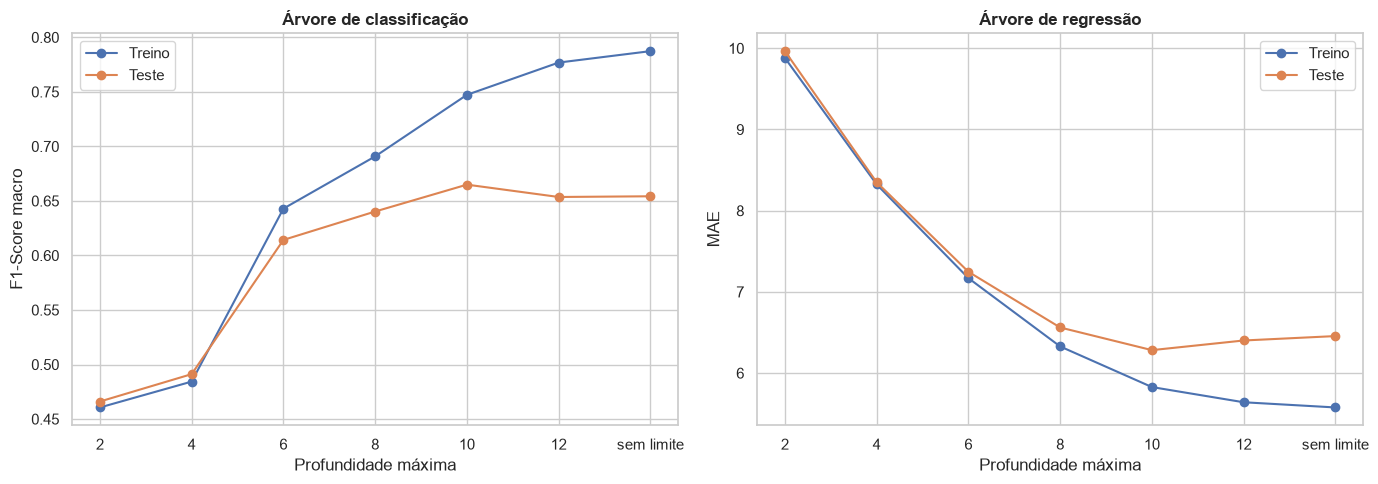

In [6]:
profundidades = [2, 4, 6, 8, 10, 12, None]
registros_complexidade = []

for profundidade in profundidades:
    arvore_c = criar_arvore_classificacao(
        criterion="entropy",
        max_depth=profundidade,
        min_samples_leaf=10,
    )
    arvore_c.fit(X_train_c, y_train_c)
    m_tr_c = calcular_metricas_classificacao(
        y_train_c,
        arvore_c.predict(X_train_c),
        classes=CLASSES,
    )
    m_te_c = calcular_metricas_classificacao(
        y_test_c,
        arvore_c.predict(X_test_c),
        classes=CLASSES,
    )

    arvore_r = criar_arvore_regressao(
        criterion="squared_error",
        max_depth=profundidade,
        min_samples_leaf=20,
        ccp_alpha=0.0,
    )
    arvore_r.fit(X_train_r, y_train_r)
    m_tr_r = calcular_metricas_regressao(y_train_r, arvore_r.predict(X_train_r))
    m_te_r = calcular_metricas_regressao(y_test_r, arvore_r.predict(X_test_r))

    registros_complexidade.append(
        {
            "Profundidade": "sem limite"
            if profundidade is None
            else profundidade,
            "F1 Macro Treino": m_tr_c["F1-Score (Macro)"],
            "F1 Macro Teste": m_te_c["F1-Score (Macro)"],
            "MAE Treino": m_tr_r["MAE"],
            "MAE Teste": m_te_r["MAE"],
            "Nós classificação": arvore_c.named_steps["model"].tree_.node_count,
            "Nós regressão": arvore_r.named_steps["model"].tree_.node_count,
        }
    )

tabela_complexidade = pd.DataFrame(registros_complexidade)
display(tabela_complexidade.round(4))
tabela_complexidade.to_csv(
    TABLES_DIR / "curva_complexidade_arvore.csv",
    index=False,
    encoding="utf-8",
)

rotulos = tabela_complexidade["Profundidade"].astype(str)
posicoes = np.arange(len(rotulos))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].plot(
    posicoes,
    tabela_complexidade["F1 Macro Treino"],
    marker="o",
    label="Treino",
)
eixos[0].plot(
    posicoes,
    tabela_complexidade["F1 Macro Teste"],
    marker="o",
    label="Teste",
)
eixos[0].set_xticks(posicoes, rotulos)
eixos[0].set_xlabel("Profundidade máxima")
eixos[0].set_ylabel("F1-Score macro")
eixos[0].set_title("Árvore de classificação", fontweight="bold")
eixos[0].legend()

eixos[1].plot(
    posicoes,
    tabela_complexidade["MAE Treino"],
    marker="o",
    label="Treino",
)
eixos[1].plot(
    posicoes,
    tabela_complexidade["MAE Teste"],
    marker="o",
    label="Teste",
)
eixos[1].set_xticks(posicoes, rotulos)
eixos[1].set_xlabel("Profundidade máxima")
eixos[1].set_ylabel("MAE")
eixos[1].set_title("Árvore de regressão", fontweight="bold")
eixos[1].legend()

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "curva_complexidade_arvore.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 4. Diagnóstico de generalização

Os números acima são consolidados na tabela abaixo. O diagnóstico
combina três evidências: o gap treino–teste, a posição do teste em
relação à média e ao desvio padrão da validação cruzada, e a estrutura
do modelo (regras fixas, profundidade e número de árvores).

| Problema | Modelo | Evidência principal | Diagnóstico |
|---|---|---|---|
| Classificação | Sistema Especialista | Cobertura de 53,9%; F1 macro 0,569 no treino e 0,562 no teste | **Cobertura parcial / alto viés estrutural**; o gap é pequeno porque as regras são fixas, mas quase metade dos casos fica sem resposta |
| Classificação | Árvore de Decisão | F1 0,747 → 0,665; CV 0,678 ± 0,030 | **Sobreajuste moderado**; o teste fica dentro de 1 DP da CV, mas o gap é maior que 2 DP |
| Classificação | Random Forest | F1 1,000 → 0,686; CV 0,684 ± 0,025 | **Overfitting de memorização**; o treino é perfeito, porém o teste reproduz a CV e o desempenho retido é o melhor |
| Classificação | Gradient Boosting | F1 0,751 → 0,668; CV 0,713 ± 0,020 | **Sinais de sobreajuste/instabilidade**; o teste fica ~2,2 DP abaixo da CV, embora o gap treino–teste seja moderado |
| Regressão | Especialista v2 | MAE 5,990 → 5,994; CV 5,990 ± 0,041 | **Bem ajustado, baixa variância**; alta interpretabilidade e erro próximo do melhor modelo |
| Regressão | Árvore de Decisão | MAE 5,828 → 6,282; CV 6,359 ± 0,036 | **Bem ajustado**; o gap de treino é visível, mas o teste é até melhor que a CV |
| Regressão | Random Forest | MAE 4,592 → 6,140; CV 6,117 ± 0,041 | **Overfitting de treino com boa generalização**; o teste coincide com a CV, mas o modelo é grande e lento |
| Regressão | Gradient Boosting | MAE 5,882 → 5,928; CV 5,919 ± 0,032 | **Bem ajustado**; menor erro de teste e gap praticamente nulo |

A leitura do gap isolado pode enganar. A Random Forest de classificação
tem o maior gap (0,314) e, ao mesmo tempo, o melhor F1 de teste (0,686).
O que ela faz é memorizar o treino e depois generalizar para um patamar
estável, confirmado pela CV (0,684). Já o Gradient Boosting tem gap
menor, mas o teste cai 0,045 em relação à CV — uma diferença de pouco
mais de dois desvios padrão. Para decidir entre os dois, portanto, não
basta olhar o gap: é preciso comparar teste e CV.

## 5. Viés e variância por família

* **Sistema especialista** — viés alto e variância zero no sentido
  estatístico: a mesma regra produz sempre a mesma saída. Na
  classificação, o viés é agravado pela cobertura parcial (53,9%); na
  regressão, o motor aditivo de 19 faixas reduz bastante esse viés e
  chega a MAE 5,99. O custo é a rigidez: não aprende interações nem se
  adapta a novos padrões sem intervenção humana.
* **Árvore de decisão** — viés menor que o especialista, variância
  maior. A curva de profundidade mostra o comportamento clássico: o
  treino continua melhorando até a árvore sem limite, enquanto o teste
  satura e piora. A poda por profundidade/folha contém a variância, mas
  não elimina o gap.
* **Random Forest** — reduz a variância pela média de muitas árvores,
  ao preço de um modelo muito maior e mais lento. O treino perfeito é
  esperado (árvores profundas), mas a generalização é estável. É a
  família com maior custo de memória/disco.
* **Gradient Boosting** — árvores rasas e encadeadas reduzem viés com
  pouca variância. É o modelo mais consistente na regressão e o melhor
  na validação cruzada de classificação, embora o teste de
  classificação tenha ficado abaixo da CV. O treino é sequencial e mais
  caro que o da árvore isolada.

## 6. Síntese

* Nenhum modelo apresenta o padrão extremo de underfitting: os erros de
  treino e teste são próximos na regressão e o F1 de teste é razoável na
  classificação.
* O maior gap de treino–teste é o da Random Forest, explicado pela
  memorização; ainda assim, o teste é consistente com a CV.
* O Gradient Boosting tem o menor MAE de teste na regressão e a melhor
  média de F1 macro na CV de classificação, com gap pequeno.
* O sistema especialista tem baixa variância, mas a classificação sofre
  com cobertura parcial; a regressão v2 é competitiva e muito mais
  interpretável.
* A escolha final não deve ser feita só pelo gap: o notebook 09 combina
  desempenho, generalização, custo e interpretabilidade.